# Лабораторная работа 05 — Предобработка данных для ML и основы аналитики

**ФИО:** Ушакова Марина Михайловна  
**Группа:** ЕТ-212

 Предобработка данных для машинного обучения (масштабирование, кодирование категорий) и основам аналитики (постановка задач, декомпозиция, выборки) в Python (pandas, scikit-learn, matplotlib).

Подготовка

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    LabelEncoder, OrdinalEncoder, OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

np.random.seed(42)
n = 800

df = pd.DataFrame({
    'Age':         np.random.randint(18, 76, n),
    'Income':      np.random.lognormal(mean=10.5, sigma=0.9, size=n).round(0),
    'Tenure':      np.random.randint(1, 61, n),
    'CreditScore': np.random.randint(300, 851, n),
    'Gender':      np.random.choice(['M', 'F'], n, p=[0.55, 0.45]),
    'Education':   np.random.choice(
                       ['High School', 'Bachelor', 'Master', 'PhD'],
                       n, p=[0.30, 0.45, 0.20, 0.05]),
    'City':        np.random.choice(
                       ['Moscow', 'SPb', 'Kazan', 'Ufa',
                        'Novosibirsk', 'Ekaterinburg'], n),
})

df.loc[0, 'Income'] = 5_000_000

churn_logit = (
    -0.8
    + 0.04 * (df['Age'] - 45)
    + 1.2 * (df['Tenure'] < 12).astype(int)
)
p_churn = 1 / (1 + np.exp(-churn_logit))
df['Churn'] = np.random.binomial(1, p_churn)

df.to_csv('bank_customers.csv', index=False)

print(df.head())
print(f"Размер: {df.shape}")
print(f"Средний Churn: {df['Churn'].mean():.3f}")
print(df.dtypes)

   Age     Income  Tenure  CreditScore Gender    Education          City  \
0   56  5000000.0      15          369      M       Master           Ufa   
1   69    24836.0      21          510      M       Master  Ekaterinburg   
2   46   133169.0      19          400      M  High School           Ufa   
3   32     6481.0      60          431      F     Bachelor           SPb   
4   60    78179.0      29          680      M     Bachelor           SPb   

   Churn  
0      0  
1      0  
2      0  
3      0  
4      0  
Размер: (800, 8)
Средний Churn: 0.371
Age              int64
Income         float64
Tenure           int64
CreditScore      int64
Gender          object
Education       object
City            object
Churn            int64
dtype: object


Часть 1. Аналитика

Задание 1.1. SMART-формулировка

Переформулируйте задачу в SMART-формате по шаблону:

> Снизить \<метрика> на \<X %> в сегменте \<сегмент> за \<срок> за счёт \<действие>

In [2]:
smart_goal = ("Снизить долю уходящих клиентов (churn_rate) в сегменте "
              "клиентов с Tenure < 12 месяцев с 45% до 35% "
              "за 6 месяцев за счёт программы онбординга и проактивных "
              "звонков в первые 3 месяца.")

print(smart_goal)

Снизить долю уходящих клиентов (churn_rate) в сегменте клиентов с Tenure < 12 месяцев с 45% до 35% за 6 месяцев за счёт программы онбординга и проактивных звонков в первые 3 месяца.


Specific-метрика — churn_rate в сегменте Tenure < 12; действие — онбординг + проактивные звонки

Measurable-целевое значение 35% против текущих ~45%; считается как доля Churn=1

Achievable-снижение на 10 п.п. за счёт известного драйвера (Tenure < 12 даёт +1.2 к логиту)

Relevant-отток напрямую влияет на LTV и доход банка

Time-bound-срок — 6 месяцев

Задание 1.2. MECE-дерево

In [3]:
decomposition_tree = {
    "Почему клиенты уходят": {
        "Клиентская база": {
            "Новые клиенты": ["new_clients_count", "new_churn_rate"],
            "Уходящие существующие": ["churn_rate", "avg_tenure_of_churned",
                                       "churned_count"],
            "Активные": ["active_clients_count"],
        },
        "Доход от клиента": {
            "Доход на клиента": ["avg_income_per_client"],
            "Частота операций": ["avg_operations_per_client"],
            "Доход уходящих vs остающихся": ["avg_income_churned",
                                              "avg_income_retained"],
        },
        "Качество обслуживания": {
            "Обращения в поддержку": ["support_calls_per_client"],
            "Скорость ответа": ["avg_response_time"],
            "Связь обращений с оттоком": ["churn_rate_among_callers"],
        },
    }
}

def print_tree(tree, level=0):
    for key, value in tree.items():
        print("  " * level + f"- {key}")
        if isinstance(value, dict):
            print_tree(value, level + 1)
        elif isinstance(value, list):
            for leaf in value:
                print("  " * (level + 1) + f"* {leaf}")

print_tree(decomposition_tree)

- Почему клиенты уходят
  - Клиентская база
    - Новые клиенты
      * new_clients_count
      * new_churn_rate
    - Уходящие существующие
      * churn_rate
      * avg_tenure_of_churned
      * churned_count
    - Активные
      * active_clients_count
  - Доход от клиента
    - Доход на клиента
      * avg_income_per_client
    - Частота операций
      * avg_operations_per_client
    - Доход уходящих vs остающихся
      * avg_income_churned
      * avg_income_retained
  - Качество обслуживания
    - Обращения в поддержку
      * support_calls_per_client
    - Скорость ответа
      * avg_response_time
    - Связь обращений с оттоком
      * churn_rate_among_callers


Взаимоисключающе? Не полностью. «Новые клиенты» и «Уходящие существующие» пересекаются с «Активные» по определению (новый клиент может быть активным). Ветки «Доход» и «Качество обслуживания» пересекаются через churn_rate_among_callers (качество влияет на доход через отток). Для строгого MECE нужно зафиксировать: активные = все, кто не ушёл; новые = пришедшие в периоде; уходящие = ушедшие в периоде.

Полное? Нет. Упущены: продуктовый портфель (число продуктов на клиента), каналы привлечения, макрофакторы/конкуренты, стоимость удержания (CAC). Их нужно добавить для полноты.

Измеримы на текущем датасете? churn_rate, avg_tenure_of_churned, avg_income_per_client, churned_count, new_clients_count — да. support_calls_per_client, avg_response_time, churn_rate_among_callers — нет, нужно запросить логи обращений в поддержку. new_clients_count без даты регистрации тоже проблематичен — нужна дата.

Задание 1.3. Типы смещений

Для каждого сценария укажите тип систематического смещения: `selection`, `survivorship`, `response`, `recall`.

1. Аналитик изучает успешные стартапы, чтобы вывести формулу успеха.
2. Опрос «довольны ли вы сервисом?» проводится на сайте банка.
3. Модель обучали на клиентах, пришедших через рекламу Google.
4. Пользователей спрашивают «сколько раз вы были в банке в прошлом году».

Ответ запишите в словарь и выведите на экран с коротким (1–2 предложения) обоснованием.

In [4]:
biases = {
    "1. Успешные стартапы → формула успеха": (
        "survivorship", "Анализируются только выжившие компании; "
        "провалившиеся не попали в выборку, поэтому выводы смещены."),
    "2. Опрос на сайте банка": (
        "selection / response", "Отвечают только те, кто зашёл на сайт и "
        "захотел ответить; недовольные и офлайн-клиенты недопредставлены."),
    "3. Обучение на клиентах из Google Ads": (
        "selection", "Выборка ограничена одним каналом привлечения; "
        "модель не обобщится на клиентов из других каналов."),
    "4. 'Сколько раз вы были в банке в прошлом году?'": (
        "recall", "Ошибка памяти: респонденты неточно вспоминают частоту "
        "событий, обычно занижают редкие и завышают частые визиты."),
}
for k, (t, why) in biases.items():
    print(f"{k}\n  → {t}: {why}\n")

1. Успешные стартапы → формула успеха
  → survivorship: Анализируются только выжившие компании; провалившиеся не попали в выборку, поэтому выводы смещены.

2. Опрос на сайте банка
  → selection / response: Отвечают только те, кто зашёл на сайт и захотел ответить; недовольные и офлайн-клиенты недопредставлены.

3. Обучение на клиентах из Google Ads
  → selection: Выборка ограничена одним каналом привлечения; модель не обобщится на клиентов из других каналов.

4. 'Сколько раз вы были в банке в прошлом году?'
  → recall: Ошибка памяти: респонденты неточно вспоминают частоту событий, обычно занижают редкие и завышают частые визиты.



Часть 2. Первичный анализ

Задание 2.1. Классификация признаков

Разделите исходные признаки (все столбцы, кроме `Churn`) на три группы:

- числовые;
- номинальные (нет порядка);
- порядковые (порядок есть).

In [5]:
numeric_cols = ['Age', 'Income', 'Tenure', 'CreditScore']
nominal_cols = ['Gender', 'City']
ordinal_cols = ['Education']

original_cols = {'Age', 'Income', 'Tenure', 'CreditScore',
                 'Gender', 'Education', 'City'}
covered = set(numeric_cols) | set(nominal_cols) | set(ordinal_cols)
assert original_cols == covered, f"Пропущены: {original_cols - covered}"
print("Все признаки распределены по типам")

Все признаки распределены по типам


Почему `Education` относится к порядковым, а `City` — к номинальным?

Education — порядковый, потому что уровни имеют естественный порядок (High School < Bachelor < Master < PhD), и этот порядок несёт смысл (более высокое образование — более высокий уровень). City — номинальный: у городов нет естественного ранга, Москва не «больше» Казани в порядковой шкале; любые числовые коды были бы произвольными.

Задание 2.2. Анализ выбросов

Выведите `describe()` для числовых столбцов. Посчитайте количество выбросов по правилу трёх сигм (`|z| > 3`) для каждого столбца.

In [6]:
print(df[numeric_cols].describe().round(1))

z_scores = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()
print((z_scores.abs() > 3).sum())

         Age     Income  Tenure  CreditScore
count  800.0      800.0   800.0        800.0
mean    47.1    67728.3    29.5        578.8
std     16.6   188315.9    17.0        159.4
min     18.0     2963.0     1.0        300.0
25%     33.0    20203.5    15.0        440.0
50%     47.5    38086.0    29.0        576.0
75%     61.0    75490.2    44.0        720.0
max     75.0  5000000.0    60.0        850.0
Age            0
Income         1
Tenure         0
CreditScore    0
dtype: int64


 В каком столбце есть выброс, какой скейлер вы выберете для этого столбца и почему?

 Выброс есть в Income (значение 5 000 000, z-score ≈ 20+). Для Income выбираю RobustScaler, потому что он центрирует по медиане и масштабирует по IQR — единственный выброс не искажает параметры преобразования. StandardScaler «раздул» бы σ и сжал все нормальные значения к нулю; MinMaxScaler прижал бы всё к 0 из-за max = 5 000 0

Часть 3. Масштабирование

Примените `MinMaxScaler`, `StandardScaler` и `RobustScaler` к столбцу `Income`. Постройте четыре гистограммы в одном ряду: исходный доход, после Min-Max, после Standard, после Robust.

Задание 3.1. Сравнение скейлеров

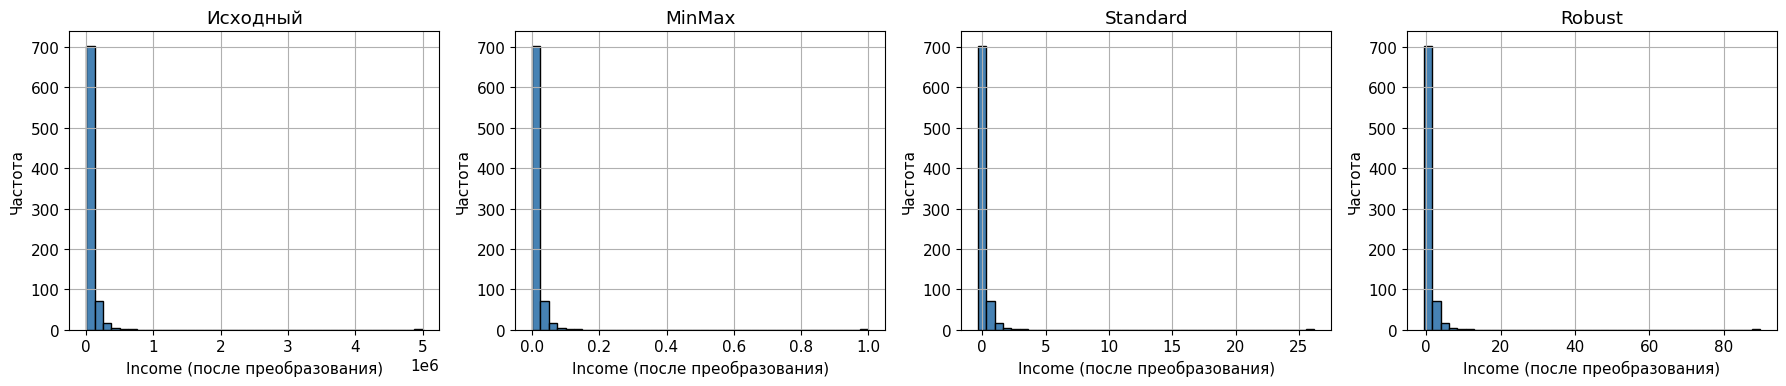

In [7]:
income = df[['Income']].values
scalers = {
    'Исходный': income,
    'MinMax':   MinMaxScaler().fit_transform(income),
    'Standard': StandardScaler().fit_transform(income),
    'Robust':   RobustScaler().fit_transform(income),
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, data) in zip(axes, scalers.items()):
    ax.hist(data, bins=40, color='steelblue', edgecolor='black')
    ax.set_title(name)
    ax.set_xlabel('Income (после преобразования)')
    ax.set_ylabel('Частота')
plt.tight_layout()
plt.show()


1. После какого скейлера форма распределения сохранилась лучше всего?
2. Какой скейлер сильнее всего пострадал от единственного выброса?
3. Какой скейлер вы выберете для `Income` в продакшене и почему?

1) Лучше всего форма распределения сохранилась после RobustScaler (и в целом после Standard — но Standard растянут из-за выброса). Robust не «схлопывает» основную массу.

2) Сильнее всего пострадал MinMaxScaler: max = 5 000 000, поэтому все нормальные значения (десятки тысяч) сжались в узкий диапазон у нуля.

3) Для Income в продакшене выбираю RobustScaler — устойчив к выбросам, которых в реальных доходах всегда хватает, и не требует удаления выбросов.

Задание 3.2. Выбор скейлера по признаку

Заполните таблицу для четырёх числовых признаков: скейлер и краткое (1–2 предложения) обоснование.

In [8]:
scaler_choice = {
    'Age': 'MinMaxScaler',
    'Income': 'RobustScaler',
    'Tenure': 'MinMaxScaler',
    'CreditScore': 'StandardScaler',
}
justification = {
    'Age': 'Ограниченный диапазон 18–75, выбросов нет — MinMax сохраняет интерпретируемость.',
    'Income': 'Логнормальное распределение с выбросами — Robust по медиане/IQR устойчив.',
    'Tenure': 'Дискретный ограниченный диапазон 1–60, выбросов нет — MinMax.',
    'CreditScore': 'Почти равномерный ограниченный диапазон 300–850, выбросов нет; Standard удобен для линейных моделей.',
}
for col in numeric_cols:
    print(f"{col}: {scaler_choice[col]} — {justification[col]}")

Age: MinMaxScaler — Ограниченный диапазон 18–75, выбросов нет — MinMax сохраняет интерпретируемость.
Income: RobustScaler — Логнормальное распределение с выбросами — Robust по медиане/IQR устойчив.
Tenure: MinMaxScaler — Дискретный ограниченный диапазон 1–60, выбросов нет — MinMax.
CreditScore: StandardScaler — Почти равномерный ограниченный диапазон 300–850, выбросов нет; Standard удобен для линейных моделей.


Часть 4. Кодирование категорий

Задание 4.1. Label и One-Hot для Gender

Закодируйте `Gender` через `LabelEncoder` и через `pd.get_dummies`. Выведите результат.

In [9]:
df['Gender_Label'] = LabelEncoder().fit_transform(df['Gender'])
df_ohe = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
print(df_ohe.head())
print(df[['Gender', 'Gender_Label']].drop_duplicates())

   Gender_F  Gender_M
0         0         1
1         0         1
2         0         1
3         1         0
4         0         1
  Gender  Gender_Label
0      M             1
3      F             0


Для каких моделей Label-кодирование допустимо, а для каких — нет? Обоснуйте.

Label-кодирование допустимо для деревьев решений, Random Forest, Gradient Boosting — они умеют находить нелинейные разбиения по значению кода, и порядок кодов не создаёт ложной линейной зависимости. Недопустимо для линейных моделей, логистической регрессии, SVM, kNN, нейросетей — они воспринимают код как число: «F=1» окажется «больше» «M=0», появится фиктивная линейная зависимость, которой в данных нет.

Задание 4.2. Ordinal-кодирование Education

`Education` — порядковый признак. Закодируйте его через `OrdinalEncoder` с **явно заданным** порядком: `High School < Bachelor < Master < PhD`.

In [10]:
edu_order = ['High School', 'Bachelor', 'Master', 'PhD']
oe = OrdinalEncoder(categories=[edu_order])
df['Education_Ord'] = oe.fit_transform(df[['Education']])
print(df[['Education', 'Education_Ord']].drop_duplicates().sort_values('Education_Ord'))

      Education  Education_Ord
2   High School            0.0
3      Bachelor            1.0
0        Master            2.0
19          PhD            3.0


Что было бы, если не задать `categories` явно? Какие значения получили бы категории и насколько это соответствует реальному порядку?

Без явного categories sklearn сортирует категории алфавитно: Bachelor=0, High School=1, Master=2, PhD=3. Это ставит High School выше Bachelor — прямо противоположно реальному порядку. Модель выучила бы бессмысленную зависимость. Явное задание порядка критично.

Задание 4.3. Frequency-кодирование City

Закодируйте `City` через частоту встречаемости.

In [11]:
freq_map = df['City'].value_counts()
df['City_Freq'] = df['City'].map(freq_map)
print(df[['City', 'City_Freq']].drop_duplicates())

            City  City_Freq
0            Ufa        115
1   Ekaterinburg        138
3            SPb        140
5    Novosibirsk        139
7         Moscow        135
16         Kazan        133


В чём главный недостаток Frequency-кодирования? В каком сценарии этот недостаток критичен?

Главный недостаток — разные категории с одинаковой частотой получают одинаковый код, модель не может их различить. Критично, когда в данных есть несколько городов с близкими частотами (например, редкие города по 2–3 клиента) — они «склеиваются» в один признак, и модель теряет информацию о том, какой именно город. Также freq-код зависит от выборки: при пересчёте на новых данных значения меняются, что ломает воспроизводимость.

Часть 5. ColumnTransformer

Задание 5.1. Полный препроцессинг

Соберите единый `ColumnTransformer`, который:

- к `Age`, `CreditScore` применяет `StandardScaler`;
- к `Income` — `RobustScaler`;
- к `Tenure` — `MinMaxScaler`;
- к `Gender`, `City` — `OneHotEncoder(drop='first')`;
- к `Education` — `OrdinalEncoder` с тем же порядком, что в задании 4.2.

Данные на train/test разделите **до** `fit`.

In [12]:
X = df.drop(columns=['Churn', 'Gender_Label', 'Education_Ord', 'City_Freq'],
            errors='ignore')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(transformers=[
    ('age_std',   StandardScaler(), ['Age']),
    ('credit_std', StandardScaler(), ['CreditScore']),
    ('income_rob', RobustScaler(),   ['Income']),
    ('tenure_mm',  MinMaxScaler(),   ['Tenure']),
    ('gender_ohe', OneHotEncoder(drop='first'), ['Gender']),
    ('city_ohe',   OneHotEncoder(drop='first'), ['City']),
    ('edu_ord',    OrdinalEncoder(categories=[edu_order]), ['Education']),
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print(X_train.shape, '->', X_train_prepared.shape)
print(X_test.shape, '->', X_test_prepared.shape)

(600, 7) -> (600, 11)
(200, 7) -> (200, 11)


1. Почему `fit_transform` применяется только к train, а к test — только `transform`?
2. Сколько столбцов даст `OneHotEncoder(drop='first')` на `Gender`? На `City`?
3. Что произойдёт, если в test встретится город, которого не было в train? Как это обрабатывается в sklearn по умолчанию и как можно изменить поведение?

1) fit_transform только на train — чтобы параметры (mean, std, min, max, медиана, IQR, список категорий) вычислялись только по обучающей выборке. Если применить fit к test, произойдёт утечка данных: информация из test попадёт в препроцессинг, метрики на test станут оптимистично завышенными, и модель не будет обобщаться на реальные новые данные.

2) Gender → 1 столбец (2 категории − 1). City → 5 столбцов (6 городов − 1).

3) Если в test встретится город, которого не было в train, по умолчанию OneHotEncoder выбросит ошибку (handle_unknown='error'). Чтобы избежать — задать handle_unknown='ignore': тогда все индикаторы для неизвестной категории будут нулями (она сольётся с базовой категорией, которую удалили через drop='first').

Часть 6. Выборки

Задание 6.1. Простая случайная и стратифицированная

Сделайте две выборки по 100 строк:

- простую случайную (`df.sample`);
- стратифицированную по `Churn` — реализуйте функцию `stratified_sample` самостоятельно.

Подсказка: `df[strat_col].value_counts(normalize=True)` даёт доли групп, а `.sample(n=..., random_state=...)` — случайную выборку внутри группы.


In [13]:
def stratified_sample(df, strat_col, n_total, random_state=42):
    rng = np.random.RandomState(random_state)
    props = df[strat_col].value_counts(normalize=True)
    parts = []
    for value, share in props.items():
        n_group = int(round(n_total * share))
        group = df[df[strat_col] == value]
        parts.append(group.sample(n=min(n_group, len(group)),
                                   random_state=rng.randint(0, 10**6)))
    out = pd.concat(parts)
    # добить до n_total, если округление дало меньше
    if len(out) < n_total:
        rest = df.drop(out.index).sample(n=n_total - len(out),
                                          random_state=rng.randint(0, 10**6))
        out = pd.concat([out, rest])
    return out.sample(frac=1, random_state=random_state).reset_index(drop=True)

s_rand = df.sample(n=100, random_state=42)
s_strat = stratified_sample(df, 'Churn', n_total=100)

print(f"Популяция:            {df['Churn'].mean():.3f}")
print(f"Случайная:            {s_rand['Churn'].mean():.3f}")
print(f"Стратифицированная:   {s_strat['Churn'].mean():.3f}")

Популяция:            0.371
Случайная:            0.320
Стратифицированная:   0.370


1. Какая выборка ближе к популяции по доле `Churn`?
2. Почему при стратификации по `Churn` столбец `Churn` нельзя оставлять среди признаков `X` при обучении модели?
1) Стратифицированная выборка ближе к популяции по доле Churn: она принудительно сохраняет пропорции классов, тогда как простая случайная может случайно недобрать редкий класс. На малых n разница особенно заметна.

2) Churn нельзя оставлять в X, потому что это целевая переменная — модель выучит её напрямую (утечка таргета), метрики будут идеальными на обучении и бесполезными в продакшене. Стратификация лишь гарантирует представленность классов, но не отменяет правило «таргет не входит в признаки».

Задание 6.2. Влияние размера выборки
Сгенерируйте по 100 выборок каждого размера: `n ∈ {20, 100, 500}`. Для каждой посчитайте **медиану** `Income` (медиана устойчива к единственному выбросу в 5 000 000, поэтому именно она покажет масштаб эффекта). Постройте `boxplot` для трёх серий и горизонтальную линию на уровне медианы по всей популяции.

/tmp/ipykernel_1156/830336494.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])


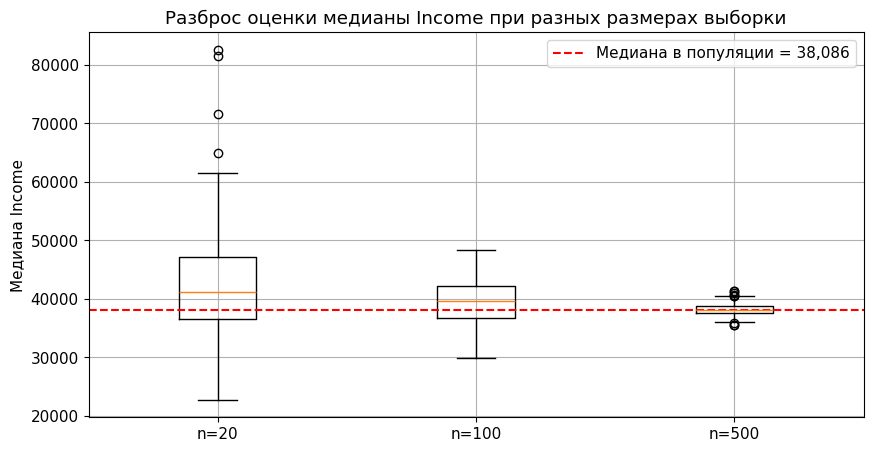

n=20: std = 10,391
n=100: std = 3,887
n=500: std = 1,138


In [14]:
sizes = [20, 100, 500]
results = {n: [] for n in sizes}
for n in sizes:
    for seed in range(100):
        results[n].append(df.sample(n=n, random_state=seed)['Income'].median())

fig, ax = plt.subplots()
ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])
ax.axhline(df['Income'].median(), color='red', linestyle='--',
           label=f"Медиана в популяции = {df['Income'].median():,.0f}")
ax.set_ylabel('Медиана Income')
ax.set_title('Разброс оценки медианы Income при разных размерах выборки')
ax.legend()
plt.show()

for n in sizes:
    print(f"n={n}: std = {np.std(results[n]):,.0f}")

Как меняется стандартное отклонение оценки медианы с ростом `n`? Согласуется ли это с формулой стандартной ошибки `σ / √n`? Что произошло бы, если бы вместо медианы вы считали среднее?

С ростом n стандартное отклонение оценки медианы уменьшается примерно как 1/√n — это согласуется с формулой стандартной ошибки σ/√n. При переходе 20→100 (×5) std падает примерно в √5 ≈ 2.2 раза, при 100→500 — ещё в √5 раз. Если бы считали среднее, единственный выброс 5 000 000 сильно смещал бы оценку при малых n (среднее не устойчиво), а с ростом n его влияние падало бы медленнее; медиана же почти не реагирует на выброс уже при n=20 — поэтому на графике видно стабильное совпадение с популяционной медианой даже на малых выборках, а разброс обусловлен только случайностью, а не выбросом.
